# PDF calculations through DISCUS

This notebook generates an inspectable DISCUS 1D PDF macro, optionally runs it, and plots the result. **You need DISCUS_SUITE installed separately.**

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from discuspdf import PDFConfig, PDFRunner

In [2]:
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
print("Project root:", ROOT)

Project root: /tmp/discus-python-nb4


## 1. Define calculation

The example GaAs unit-cell file was adapted from a published DISCUS file-format example. Replace it with your validated `.cll` file if needed.

In [3]:
config = PDFConfig(
    structure=ROOT / "examples" / "gaas.cll",
    supercell=(5, 5, 5),
    rmax=12.0,
    dr=0.02,
    qmax=25.0,
    qsig=0.0,
    radiation="xray",
)
runner = PDFRunner(runs_directory=ROOT / "runs")

## 2. Inspect the generated macro before running

In [4]:
prepared = runner.prepare(config)
print((prepared.directory / "run.mac").read_text())

# Generated by discuspdf: 1D atomic PDF calculation (DISCUS v6.x)
discus
read
cell model.cll,5,5,5
powder
reset
xray
set axis,q
set calc,debye
set qmin,0.5
set qmax,25
set dq,0.01
set delta,0
set wvle,1.5406
run
exit
output
outf result.pdf
form pdf, r, 0.0, 12, 0.02
value PDF
run
exit
exit



## 3. Execute the inspected calculation

Switch `RUN_DISCUS` to True only after verifying the macro works with your installed executable and version.

`runner.execute(prepared)` runs **exactly the macro inspected in section 2** (its staged files and hashes are re-verified before launch). Use `runner.run(new_config)` only for *new* configurations, which prepares a fresh run directory first. The sweep in section 4 therefore uses `runner.run(replace(config, ...))`.

Saved: /tmp/discus-python-nb4/runs/20261031T194911Z_2ca7c406/result.pdf


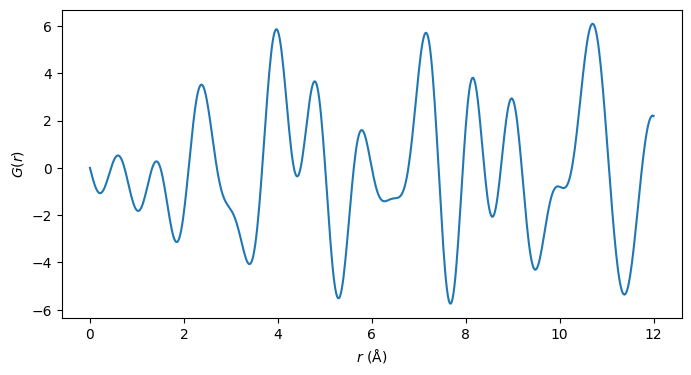

In [5]:
RUN_DISCUS = True  # enabled after validating the macro against DISCUS_SUITE 6.23.01
if RUN_DISCUS:
    result = runner.execute(prepared)
    print("Saved:", result.output)
    result.plot()
    plt.show()

## 4. Sweep Qmax and compare curves

Every run has its own directory, including logs and parameter metadata.

In this DISCUS 6.23.01 setup, G(r) did not change for any Qmax from 10 to 60 Å⁻¹ (checked at 10, 12, 14, 15, 30 and 60; identical to floating-point precision), so the sweep below stops at 10 Å⁻¹, the first value on that plateau. Below it the curves differ clearly. Why the transform stops responding to Qmax is not yet understood; treat Qmax above about 10 Å⁻¹ as having no effect here.

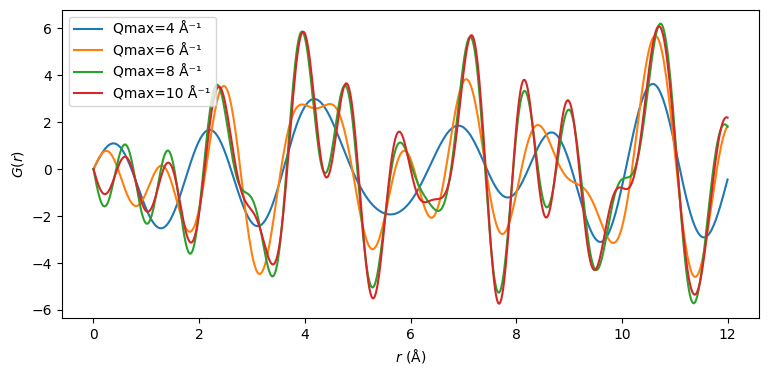

In [6]:
from dataclasses import replace
if RUN_DISCUS:
    fig, ax = plt.subplots(figsize=(9, 4))
    for qmax in (4.0, 6.0, 8.0, 10.0):
        run = runner.run(replace(config, qmax=qmax))
        run.plot(ax=ax, label=f"Qmax={qmax:g} Å⁻¹")
    plt.show()